# Hydrology Lab — Environmental Science for Sustainable Development

Notebook outline based on `water lab-1.pdf`. Complete the analysis in Python using the supplied `.mat` data and the logic in `watershedsearch.m` and `stepdown.m`. Questions below are taken from the lab handout; responses and Python code are left open.

**Plotting reminder:** Title plots, label axes, and include colorbars and legends where applicable. MATLAB uses one-based indexing; check index and axis order when translating to Python.

## Setup and data files

Use `australia_rain.mat`, `bangladesh_topography.mat`, `watershedsearch.m`, and `stepdown.m` from this lab folder. Load the data and inspect variable names, shapes, coordinate order, and missing values.

Run Jupyter from this lab folder, or set `LAB3_DATA_DIR` to the folder containing the two `.mat` files. The Python examples use NumPy zero-based indexing.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle
from scipy.io import loadmat
from scipy import stats

# Run Jupyter from the lab folder, or set LAB3_DATA_DIR to that folder.
data_dir = Path(os.environ.get("LAB3_DATA_DIR", ".")).expanduser().resolve()

australia = loadmat(data_dir / "australia_rain.mat")
rainfall = australia["rainfall"]  # lat × lon × year × month
lat = australia["lat"].ravel()
lon = australia["lon"].ravel()
year = australia["year"].ravel()
print(australia["key"].item())
print("rainfall:", rainfall.shape, "lat/lon/year:", lat.shape, lon.shape, year.shape)


THIS IS THE (1970-2007) TIME SERIES OF GRIDDED RAINFALL (MONTHLY AVERAGE) FROM THE AUSTRALIAN BUREAU OF METEROLOGY. DIMENSIONS OF THE MATRIX "RAINFALL" ARE (LAT LON YEAR MONTH).
rainfall: (139, 178, 38, 12) lat/lon/year: (139,) (178,) (38,)


# 1. Australian rainfall statistics

## 1.1 Higher dimension arrays

Create same-sized arrays `A` and `B`, stack them in a third dimension as `C`, and explore indexing, a fourth dimension, and dimension removal (MATLAB `squeeze`).

In [2]:
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])
C = np.stack((A, B), axis=2)  # MATLAB cat(3,A,B)
K = np.arange(1000).reshape(10, 10, 10)
print("C shape:", C.shape, "layers:\n", C[:, :, 0], "\n", C[:, :, 1])
print("K elements:", K.size, "vertices:", K[0, 0, 0], K[-1, -1, -1])
print("Eight central entries:\n", K[4:6, 4:6, 4:6])
D = np.stack((C, 3 * C), axis=3)  # MATLAB cat(4,C,3*C)
print("D shape:", D.shape)
try:
    np.stack((C, C[:, :-1, :]), axis=3)
except ValueError as exc:
    print("Mismatched dimensions:", exc)
g = C[0, 0, :]  # NumPy drops the two indexed axes automatically
print("g shape:", g.shape, "g:", g)


C shape: (2, 2, 2) layers:
 [[1 2]
 [3 4]] 
 [[5 6]
 [7 8]]
K elements: 1000 vertices: 0 999
Eight central entries:
 [[[444 445]
  [454 455]]

 [[544 545]
  [554 555]]]
D shape: (2, 2, 2, 2)
Mismatched dimensions: all input arrays must have the same shape
g shape: (2,) g: [1 5]


### Questions: array dimensions and indexing

> How does Matlab display a 3D array? If you had a 10 by 10 by 10 array K, how many elements would it have?

**Response:**

MATLAB displays a three-dimensional array as a series of two-dimensional pages, labeled by the third index (for example, `K(:,:,1)` and `K(:,:,2)`). A `10 × 10 × 10` array has **1,000 elements**.


> What command would you use to see only the entry at a vertex? Give two examples.

**Response:**

Two vertex entries are `K(1,1,1)` and `K(10,10,10)` in MATLAB. With NumPy's zero-based indexing, the same entries are `K[0,0,0]` and `K[9,9,9]` (or `K[-1,-1,-1]`).


> What about the command to look at the eight elements in the very center of the array? Draw a diagram of where these eight entries are in the array.

**Response:**

The eight central entries are `K(5:6,5:6,5:6)` in MATLAB, or `K[4:6,4:6,4:6]` in Python. Each of the two central layers contains a 2 × 2 square:

```text
          k = 5                       k = 6
      j = 5   j = 6               j = 5   j = 6
i = 5 (5,5,5) (5,6,5)      i = 5 (5,5,6) (5,6,6)
i = 6 (6,5,5) (6,6,5)      i = 6 (6,5,6) (6,6,6)
```


### Question: incompatible array shapes

> Try cat(4, C, 3*C). Try it with another array that is not the same size. What happens? Explain why.

**Response:**

`cat(4,C,3*C)` creates a four-dimensional array whose fourth dimension has size 2; for the example here, its shape is `2 × 2 × 2 × 2`. An array with a different size along any of the first three dimensions raises a dimension-mismatch error because concatenation along dimension 4 can change only that dimension. NumPy's equivalent is `np.stack((C, 3*C), axis=3)`, which likewise requires equal input shapes.



## 1.2 Data: spatial variation

Load `australia_rain.mat`; inspect `key`, `rainfall`, `lat`, `lon`, and `year`. Check whether longitude belongs on the x-axis and latitude on the y-axis. Plot January 1970 with geographic axes and a colorbar. All rainfall maps use the same land mask (cells with positive rainfall in at least one month) and tight bounds. This changes display only, not the rainfall calculations.

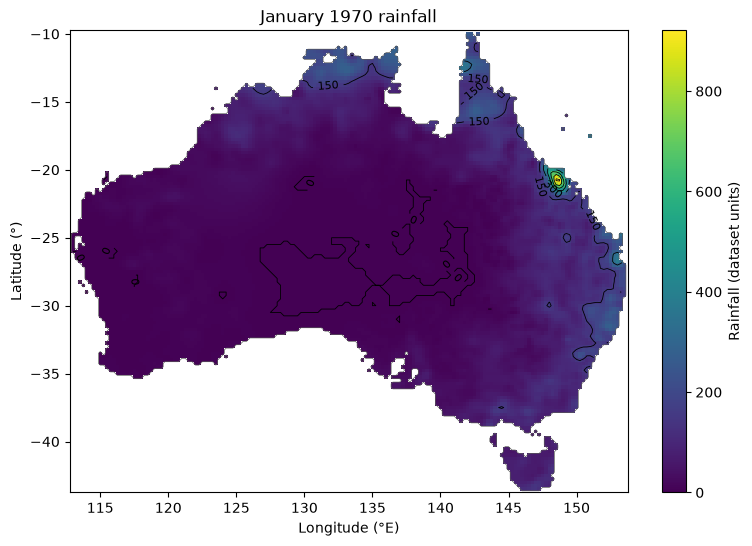

In [3]:
# The dataset uses zero rainfall offshore and has additional offshore NaNs in later years.
# A mask built across all years keeps the same visible land area in every map.
land_mask = np.any(rainfall > 0, axis=(2, 3))
land_rows, land_cols = np.where(land_mask)

def rain_map(ax, field, title, *, levels=None, vmin=None, vmax=None, cmap="viridis",
             colorbar_label="Rainfall (dataset units)"):
    # Array order is (latitude, longitude); plotting takes (x=lon, y=lat).
    visible = np.ma.masked_where(~land_mask | ~np.isfinite(field), field)
    mesh = ax.pcolormesh(lon, lat, visible, shading="auto", cmap=cmap,
                         vmin=vmin, vmax=vmax)
    ax.set(title=title, xlabel="Longitude (°E)", ylabel="Latitude (°)")
    ax.contour(lon, lat, land_mask.astype(int), levels=[0.5], colors="0.35", linewidths=0.5)
    ax.set_xlim(lon[land_cols.min()] - 0.25, lon[land_cols.max()] + 0.25)
    ax.set_ylim(lat[land_rows.min()] - 0.25, lat[land_rows.max()] + 0.25)
    plt.colorbar(mesh, ax=ax, label=colorbar_label)
    if levels is not None:
        contours = ax.contour(lon, lat, visible, levels=levels, colors="black", linewidths=0.6)
        ax.clabel(contours, inline=True, fontsize=8)  # Extra credit 1
    return mesh

jan_1970 = rainfall[:, :, np.flatnonzero(year == 1970)[0], 0]
fig, ax = plt.subplots(figsize=(9, 6))
rain_map(ax, jan_1970, "January 1970 rainfall", levels=6)
plt.show()


### Extra credit, part 1

> Figure out how to label your contours with numbers placed on the contours (like most contour maps).

**Response / Python approach:**

Use Matplotlib's `clabel` on the contour object returned by `contour`: `contours = ax.contour(lon, lat, field, levels=6); ax.clabel(contours, inline=True, fontsize=8)`. The January 1970 plotting cell already does this with its land-masked field.

### January and June climatologies

Compute the mean January field across years and the corresponding June field. Plot both with titles, axes, and colorbars.

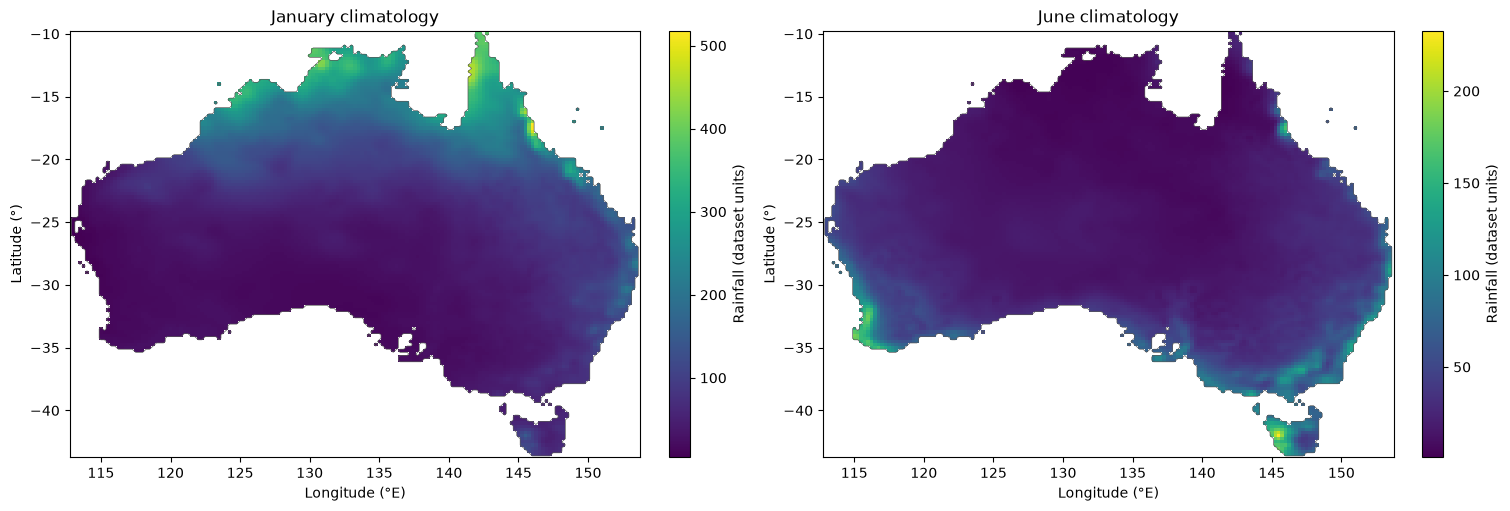

In [4]:
jan_climatology = np.nanmean(rainfall[:, :, :, 0], axis=2)
jun_climatology = np.nanmean(rainfall[:, :, :, 5], axis=2)
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
rain_map(axes[0], jan_climatology, "January climatology")
rain_map(axes[1], jun_climatology, "June climatology")
plt.show()


### Questions: monthly rainfall

> How does the rainfall in 1970 compare with the average January climatology (the mean January field across all years)? Compare the climatologies for January and June.

**Response:**

Across the 11,727 cells in the notebook's Australia land mask, January 1970 averages **43.5** dataset units versus **86.1** for the 1970–2007 January climatology. Only about **17%** of land cells exceed their local January climatology. The north and much of the interior are markedly drier in January 1970; parts of the southeast are wetter than their usual January. These are simple averages across grid cells, without area weighting.

The January climatology is much wetter in northern Australia, consistent with summer monsoon rainfall. June is much drier in the north but wetter in the southwest and Tasmania. Across land cells, the mean January and June fields average **86.1** and **25.5** dataset units, respectively; the national contrast conceals the southern winter-rainfall pattern.

### Annual climatology, 2006 rainfall, and anomalies

Average over both year and month for annual climatology. Find 2006 using `year`; plot 2006 and the climatology on a common color scale. Then plot absolute and relative 2006 anomalies. Include 2006 in the climatology.

C:\Users\theaa\AppData\Local\Temp\ipykernel_35640\2089132538.py:2: RuntimeWarning: Mean of empty slice
  annual_by_year = np.nanmean(rainfall, axis=3)


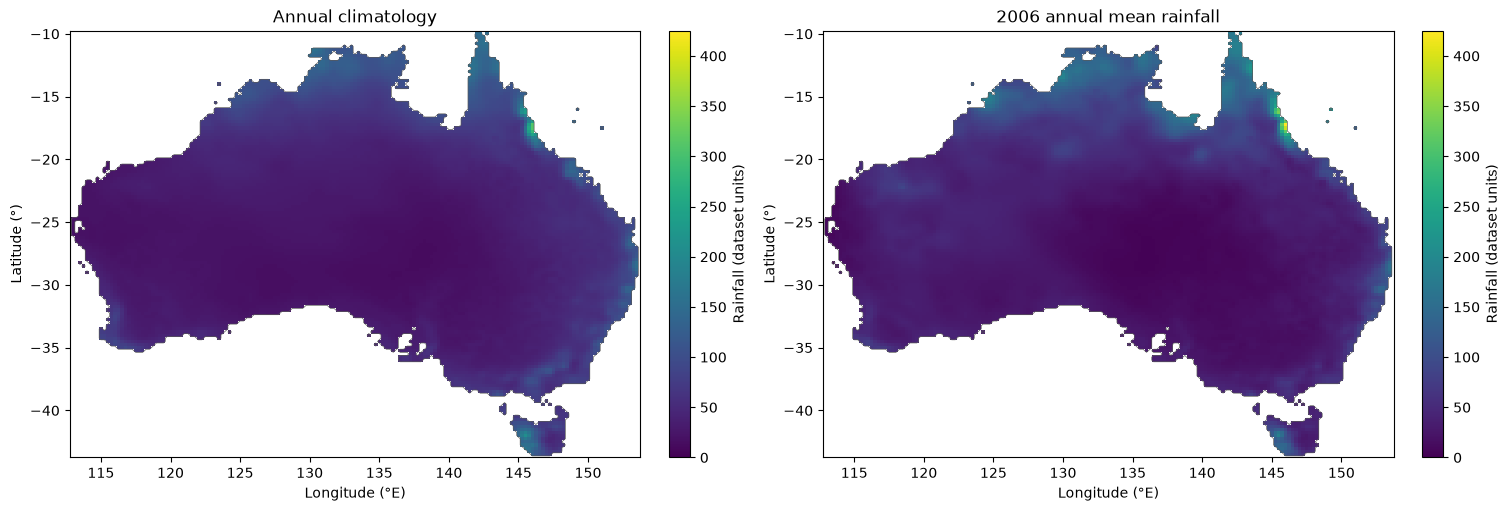

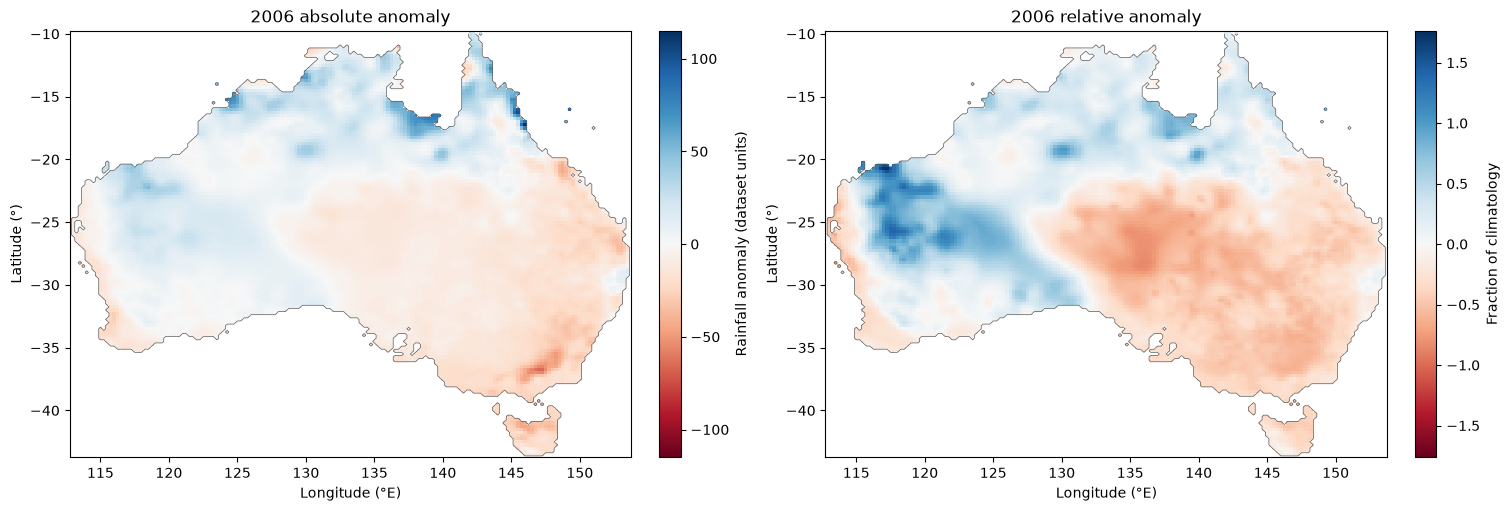

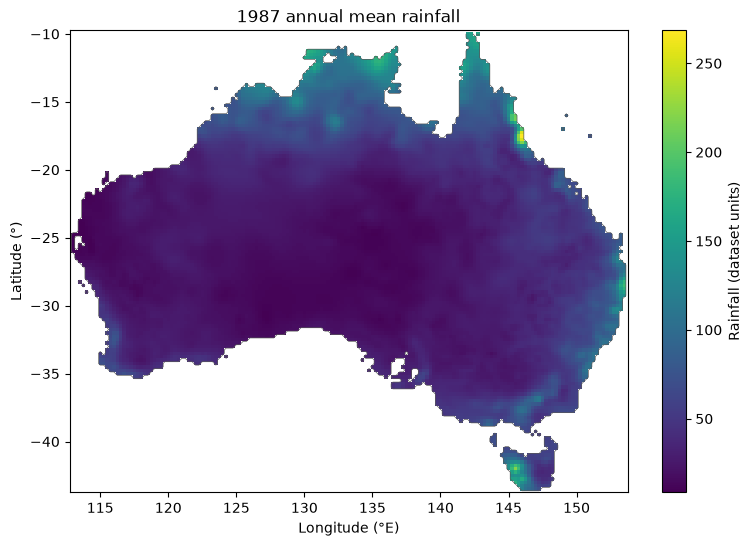

In [5]:
# The year axis includes 2006 in both climatologies.
annual_by_year = np.nanmean(rainfall, axis=3)
annual_climatology = np.nanmean(annual_by_year, axis=2)
index_2006 = np.flatnonzero(year == 2006)[0]
assert index_2006.size == 1
rain_2006 = annual_by_year[:, :, index_2006.item()]
common_max = np.nanmax((np.nanmax(annual_climatology), np.nanmax(rain_2006)))
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
rain_map(axes[0], annual_climatology, "Annual climatology", vmin=0, vmax=common_max)
rain_map(axes[1], rain_2006, "2006 annual mean rainfall", vmin=0, vmax=common_max)
plt.show()

absolute_anomaly = rain_2006 - annual_climatology
relative_anomaly = np.divide(absolute_anomaly, annual_climatology,
                             out=np.full_like(absolute_anomaly, np.nan),
                             where=annual_climatology > 0)
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
abs_limit = np.nanmax(np.abs(absolute_anomaly))
rel_limit = np.nanmax(np.abs(relative_anomaly))
rain_map(axes[0], absolute_anomaly, "2006 absolute anomaly",
         vmin=-abs_limit, vmax=abs_limit, cmap="RdBu",
         colorbar_label="Rainfall anomaly (dataset units)")
rain_map(axes[1], relative_anomaly, "2006 relative anomaly",
         vmin=-rel_limit, vmax=rel_limit, cmap="RdBu",
         colorbar_label="Fraction of climatology")
plt.show()

index_1987 = np.flatnonzero(year == 1987)[0]
assert index_1987.size == 1
fig, ax = plt.subplots(figsize=(9, 6))
rain_map(ax, annual_by_year[:, :, index_1987.item()], "1987 annual mean rainfall")
plt.show()


### Questions: 2006 drought

> How does the 2006 rainfall compare to the average climatology of the period?

**Response:**

The land-cell average annual rainfall in 2006 is **42.6** dataset units, close to the **43.1** long-run annual climatology, but the pattern is uneven. Northern Australia is generally wetter than its climatology, while the southeast and Tasmania are drier. About **54%** of land cells have a negative 2006 anomaly. Thus the near-zero Australia-wide average masks a strong regional drought.

> Which regions in Australia were hardest hit by the drought (in absolute rainfall terms)? What about as a fraction of the climatology?

**Response:**

In **absolute rainfall terms**, the largest coherent shortfall is in southeastern Australia, especially Victoria and adjacent areas, with Tasmania also below average. The most negative single land-cell anomaly in this grid is about **−66.5** dataset units near **36.75°S, 147°E**. In the southeast zone used for this comparison, the 2006 mean is **26.5** versus a climatological **43.7**, a shortfall of about **17.2** units.

As a **fraction of the local climatology**, the southeast remains strongly affected (roughly **39%** below its zone climatology), and some drier interior cells have still larger percentage deficits. The most negative single-cell relative anomaly is about **−85%** near **28.25°S, 136°E** in central South Australia. Percentage extremes in normally dry cells should be interpreted alongside their small baseline rainfall; they need not be the largest absolute water deficits.

## 1.3 Statistics: inter-temporal variation

Plot annual climatology with a continent boundary mask; mark and label Darwin and Melbourne. Build annual rainfall series for both cities and check their lengths against `year`.

Nearest grid cells: {'Darwin': (np.float64(-12.5), np.float64(130.75)), 'Melbourne': (np.float64(-37.75), np.float64(145.0))}


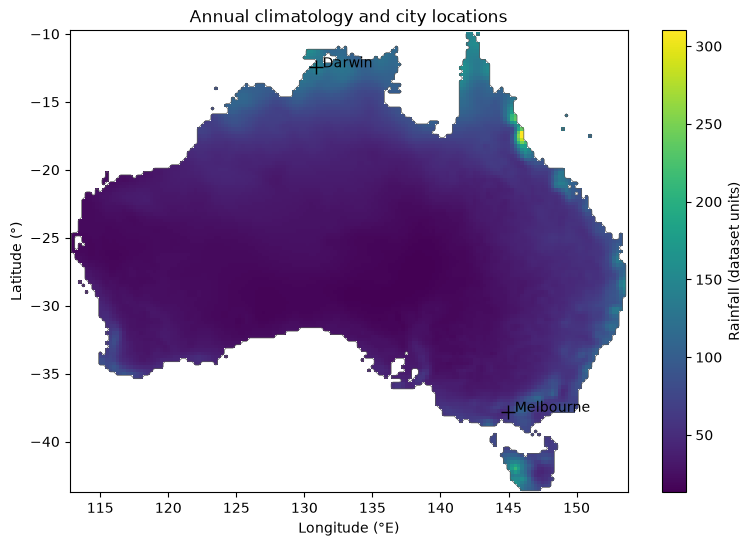

In [6]:
# Nearest grid cells to city centers, in (latitude, longitude) order.
city_coords = {"Darwin": (-12.46, 130.84), "Melbourne": (-37.81, 144.96)}
city_indices = {name: (np.abs(lat - latitude).argmin(), np.abs(lon - longitude).argmin())
                for name, (latitude, longitude) in city_coords.items()}
darwin = annual_by_year[city_indices["Darwin"]].reshape(-1)
melbourne = annual_by_year[city_indices["Melbourne"]].reshape(-1)
assert darwin.shape == melbourne.shape == year.shape
print("Nearest grid cells:", {name: (lat[i], lon[j]) for name, (i, j) in city_indices.items()})

fig, ax = plt.subplots(figsize=(9, 6))
rain_map(ax, annual_climatology, "Annual climatology and city locations")
for name, (latitude, longitude) in city_coords.items():
    ax.plot(longitude, latitude, "k+", markersize=10)
    ax.text(longitude + 0.5, latitude, name, color="black")
plt.show()


### Question: city climates

> Which city is in a drier climate?

**Response:**

**Melbourne** is drier in this dataset. At the nearest grid cells used by the notebook, the 1970–2007 annual mean is about **58.4** dataset units for Melbourne and **140.3** for Darwin. These are averages of the gridded series, not station measurements at the city centers.

### Correlation and ordinary least squares

Plot both annual series, annotate their correlation, and estimate Darwin rainfall from Melbourne rainfall with an intercept. Compare a library OLS fit with a manual calculation.

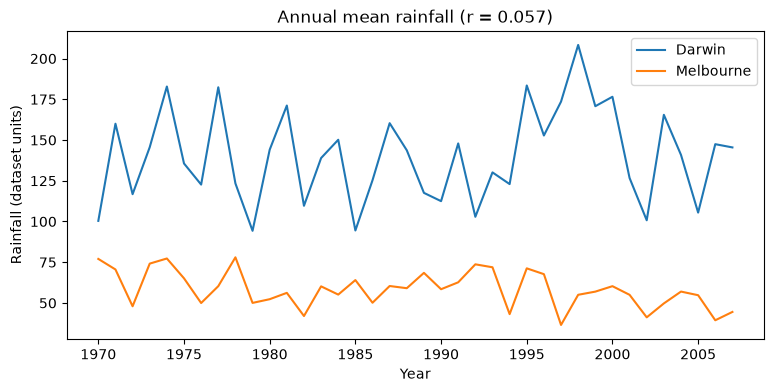

Library [intercept, slope]: 131.80197499258787 0.1463677347165008
Manual  [intercept, slope]: [131.80197499   0.14636773]
Slope standard error (extra credit): 0.4242533803271902


In [7]:
valid = np.isfinite(darwin) & np.isfinite(melbourne)
x = melbourne[valid]
y = darwin[valid]
year_valid = year[valid]
correlation = np.corrcoef(x, y)[0, 1]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(year_valid, y, label="Darwin")
ax.plot(year_valid, x, label="Melbourne")
ax.set(title=f"Annual mean rainfall (r = {correlation:.3f})", xlabel="Year",
       ylabel="Rainfall (dataset units)")
ax.legend()
plt.show()

X = np.column_stack((np.ones_like(x), x))
betas_library = stats.linregress(x, y)
betas_manual = np.linalg.solve(X.T @ X, X.T @ y)
print("Library [intercept, slope]:", betas_library.intercept, betas_library.slope)
print("Manual  [intercept, slope]:", betas_manual)
np.testing.assert_allclose(betas_manual, [betas_library.intercept, betas_library.slope])
print("Slope standard error (extra credit):", betas_library.stderr)


### Questions: regression

> Check that beta matlab and beta manual are the same and report the coefficients. Comment on the estimate and your interpretation of it.

**Response:**

The library and manual OLS calculations agree (to floating-point precision): **intercept = 131.802** and **slope = 0.1464**. With Darwin rainfall as the outcome and Melbourne rainfall as the predictor, the fitted equation is `Darwin ≈ 131.802 + 0.1464 × Melbourne` in the dataset's rainfall units. A one-unit increase in Melbourne's annual mean is associated with only about 0.146 additional units in Darwin's fitted mean. The sample correlation is **0.057**, so this linear association is extremely weak; the regression does not establish a causal effect.

### Extra credit, part 2

> See help regress and figure out how to quantify the uncertainty in the estimate. Report the commands you use.

**Response / Python commands:**

In Python, `fit = stats.linregress(melbourne, darwin)` supplies `fit.stderr` for the slope, `fit.intercept_stderr` for the intercept, and `fit.pvalue`. Here the slope standard error is **0.424**, the two-sided p-value is **0.732**, and a 95% t interval with 36 degrees of freedom is approximately **[−0.714, 1.007]**. The interval includes zero, so these data do not resolve the slope's sign. The commands are:

```python
fit = stats.linregress(melbourne, darwin)
t_critical = stats.t.ppf(0.975, df=len(year) - 2)
slope_ci = (fit.slope - t_critical * fit.stderr,
            fit.slope + t_critical * fit.stderr)
```

### Rainfall distributions

Plot Melbourne's annual rainfall histogram. Fit Poisson and normal distributions, display each fitted distribution against the histogram on a compatible scale, and compare the fits.

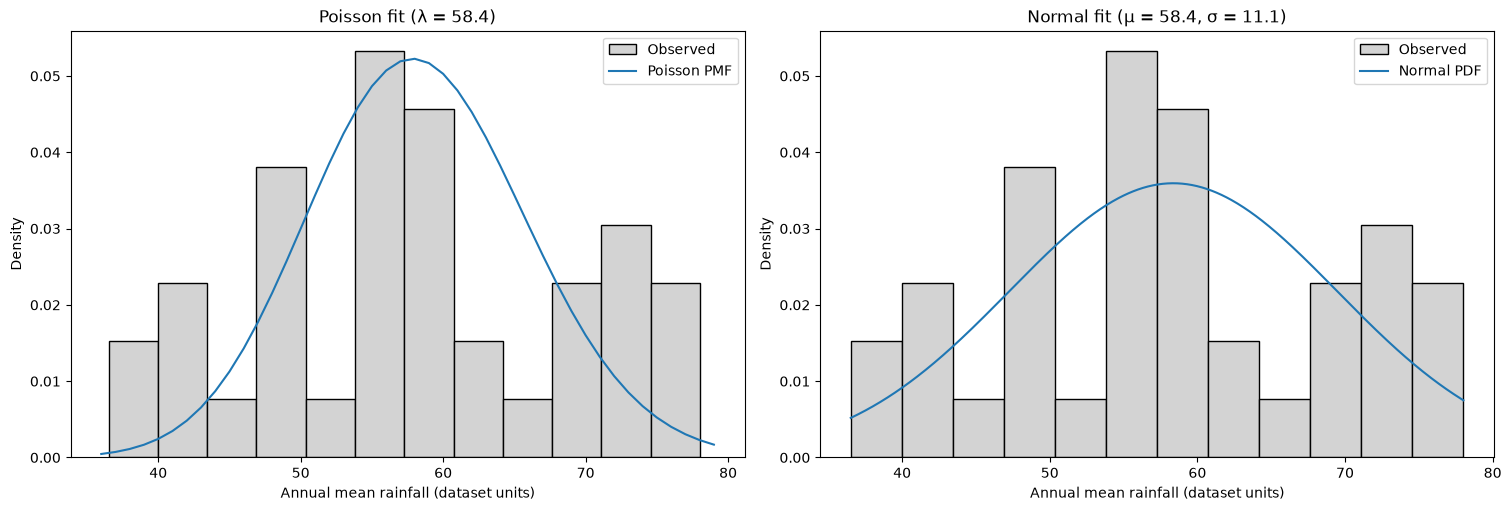

In [8]:
x = melbourne[np.isfinite(melbourne)]
lambda_hat = x.mean()  # Poisson MLE; the model assumes integer counts.
mu_hat, sigma_hat = stats.norm.fit(x)
support = np.arange(max(0, int(np.floor(x.min()))), int(np.ceil(x.max())) + 1)
smooth_support = np.linspace(x.min(), x.max(), 500)
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
for ax in axes:
    ax.hist(x, bins=12, density=True, color="lightgray", edgecolor="black", label="Observed")
    ax.set(xlabel="Annual mean rainfall (dataset units)", ylabel="Density")
axes[0].plot(support, stats.poisson.pmf(support, lambda_hat), label="Poisson PMF")
axes[0].set_title(f"Poisson fit (λ = {lambda_hat:.1f})")
axes[1].plot(smooth_support, stats.norm.pdf(smooth_support, mu_hat, sigma_hat),
             label="Normal PDF")
axes[1].set_title(f"Normal fit (μ = {mu_hat:.1f}, σ = {sigma_hat:.1f})")
for ax in axes:
    ax.legend()
plt.show()


### Questions: distribution fit

> What kind of distribution does this look like to you?

**Response:**

Melbourne's 38 annual mean values form a roughly symmetric, single-peaked distribution. The sample mean is **58.4**, the sample standard deviation is **11.2**, and the sample skewness is about **0.01**. The small sample makes fine details of the shape uncertain.

> Does Melbourne’s annual rainfall look like it’s distributed like a Poisson random variable?

**Response:**

A Poisson model is a poor match. Poisson outcomes are nonnegative **integer counts**, whereas annual mean rainfall is continuous. It also constrains the variance to equal the mean: the fitted Poisson variance would be about **58.4**, but Melbourne's sample variance is about **126.6**. The Poisson curve is therefore too narrow for the observed spread.

> Compare your two plots and comment on which parametric distribution (normal or Poisson) better characterizes the inter-temporal variation in annual rainfall over Melbourne.

**Response:**

Of these two candidates, the **normal distribution** better describes the roughly symmetric interannual spread in the histogram. It is still only an approximation: annual rainfall cannot be negative, and 38 years are too few to establish a precise distribution or tail behavior. The conclusion is a visual and moment-based comparison, not a formal model-selection test.

# 2. A watershed in Bangladesh

## 2.1 Data

Load `bangladesh_topography.mat` and inspect `topo`. Reproduce the two nested crops in Python, accounting for MATLAB's inclusive, one-based slices. Plot all three maps side by side, orient north upward, and draw rectangles around the cropped regions.

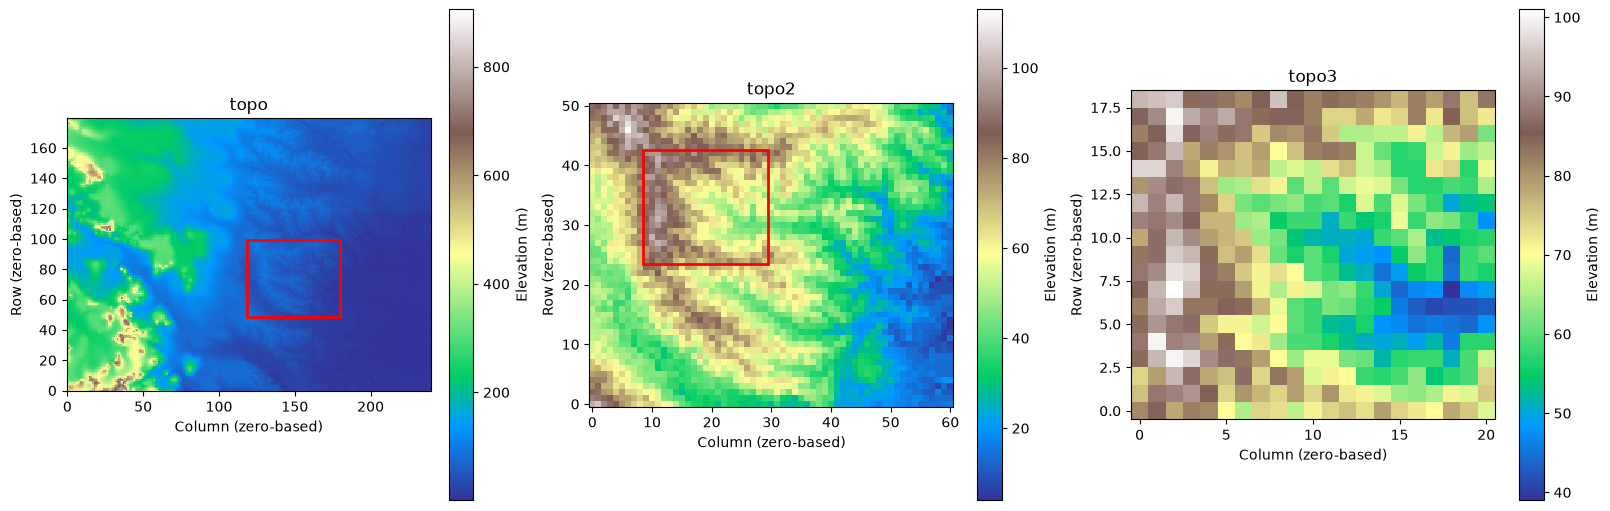

In [9]:
topo = loadmat(data_dir / "bangladesh_topography.mat")["topo"]
# MATLAB topo(50:100,120:180), then topo2(25:43,10:30).
topo2 = topo[49:100, 119:180]
topo3 = topo2[24:43, 9:30]
assert topo2.shape == (51, 61) and topo3.shape == (19, 21)
fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
for ax, field, title in zip(axes, (topo, topo2, topo3), ("topo", "topo2", "topo3")):
    image = ax.imshow(field, origin="lower", cmap="terrain", interpolation="nearest")
    ax.set(title=title, xlabel="Column (zero-based)", ylabel="Row (zero-based)")
    ax.set_aspect("equal")
    plt.colorbar(image, ax=ax, label="Elevation (m)")
axes[0].add_patch(Rectangle((118.5, 48.5), 61, 51, fill=False, edgecolor="red", linewidth=2))
axes[1].add_patch(Rectangle((8.5, 23.5), 21, 19, fill=False, edgecolor="red", linewidth=2))
plt.show()


## 2.2 Modeling downhill flow

Translate the supplied `stepdown.m` function and `watershedsearch.m` script to Python. Run the watershed search on `topo3`, inspect the `shed` mask, and overlay it on topography. Estimate watershed area from the approximately 1 km × 1 km grid cells and convert to square miles.

The original `stepdown.m` chooses the first minimum in column-first order. Flat integer elevations can create cycles, so the Python translation detects and excludes cyclic paths; inspect the reported count before interpreting the mask.

Watershed: 244 cells ≈ 244 km² ≈ 94.21 mi²
Paths stopped on elevation-tie cycles: 0


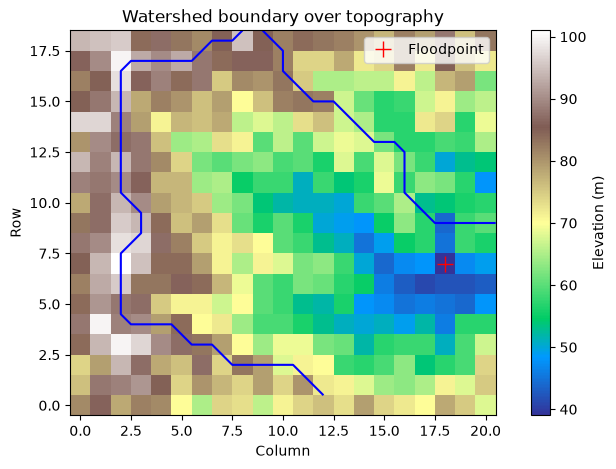

In [10]:
def stepdown(neighborhood):
    """Return (row, column) offsets matching stepdown.m's column-first tie order."""
    if neighborhood.shape != (3, 3):
        raise ValueError("stepdown requires a 3 x 3 neighborhood")
    min_rows = np.argmin(neighborhood, axis=0)
    min_values = neighborhood[min_rows, np.arange(3)]
    col = int(np.argmin(min_values))
    return int(min_rows[col] - 1), col - 1


def watershed_search(elevation):
    """Follow each cell to the specified MATLAB floodpoint; break tie cycles."""
    padded = np.pad(elevation, 1, mode="constant", constant_values=101)
    target = (8, 19)  # MATLAB topo4(9,20), converted to zero-based indexes.
    shed = np.zeros(elevation.shape, dtype=np.uint8)
    cycles = 0
    for row in range(1, padded.shape[0] - 1):
        for col in range(1, padded.shape[1] - 1):
            current = (row, col)
            visited = set()
            while current not in visited:
                visited.add(current)
                r, c = current
                dr, dc = stepdown(padded[r - 1:r + 2, c - 1:c + 2])
                if (dr, dc) == (0, 0):
                    break
                current = (r + dr, c + dc)
            else:
                cycles += 1
                continue
            if current == target:
                shed[row - 1, col - 1] = 1
    return shed, cycles


assert stepdown(np.array([[1, 1, 1], [1, 0, 1], [-1, 2, 3]])) == (1, -1)
shed, cycle_count = watershed_search(topo3)
area_km2 = int(shed.sum())  # Each DEM cell is approximately 1 km².
area_mi2 = area_km2 * 0.3861021585
print(f"Watershed: {area_km2} cells ≈ {area_km2} km² ≈ {area_mi2:.2f} mi²")
print("Paths stopped on elevation-tie cycles:", cycle_count)
fig, ax = plt.subplots(figsize=(9, 5))
image = ax.imshow(topo3, origin="lower", cmap="terrain", interpolation="nearest")
ax.contour(shed, levels=[0.5], colors="blue", origin="lower")
ax.plot(18, 7, "r+", markersize=12, label="Floodpoint")
ax.set(title="Watershed boundary over topography", xlabel="Column", ylabel="Row")
ax.legend()
plt.colorbar(image, ax=ax, label="Elevation (m)")
plt.show()


### Questions: watershed output

> Run watershedsearch, it should produce a new matrix shed. Examine this matrix, does it look right?

**Response:**

> Now figure out how many square miles the watershed is.

**Response:**

## 2.3 A monsoon

### Uniform rainfall and floodpoint capacity

Assume uniform rain over `topo3`, 10% infiltration, instant runoff, and a 1 km × 1 km floodpoint. Work out the rainfall threshold for one meter of water at the floodpoint.

In [11]:
cell_area_m2 = 1_000_000  # 1 km × 1 km
flood_depth_m = 1.0
runoff_fraction = 0.9
if area_km2 == 0:
    raise ValueError("The watershed mask is empty; inspect the flow algorithm")
flood_volume_m3 = cell_area_m2 * flood_depth_m
uniform_rain_threshold_m = flood_volume_m3 / (area_km2 * cell_area_m2 * runoff_fraction)
print(f"Uniform rainfall threshold: {uniform_rain_threshold_m:.4f} m "
      f"({uniform_rain_threshold_m * 1000:.1f} mm)")


Uniform rainfall threshold: 0.0046 m (4.6 mm)


### Questions: uniform monsoon

> How much rain can the region receive before the 1 km x 1 km floodpoint is inundated with one meter of water?

**Response:**

> You might wish to comment on this assumption. How strong is it and why?

**Response:**

### Extra credit, part 3

> Describe how you would write a program so that the lowest region of the watershed ”filled up” with water realistically, with water spilling over into other grids.

**Response:**

### Spatially varying ten-day rainstorm

Generate `monsoon` with the shape of `topo3` and rainfall uniformly distributed from 0 to 1 meter. Apply the `shed` mask and 0.9 runoff fraction; sum watershed runoff, calculate the average ten-day flow rate through a 1 km wide channel under the stated steady-state assumption, and overlay `totalrain` on topography.

The notebook computes volumetric discharge in m³/s. Channel width alone does not specify water depth or speed.

Rain on watershed: 131,037,908 m³
Runoff volume: 117,934,117 m³
Average discharge over ten days: 136.50 m³/s
A 1 km channel width alone does not determine water depth or velocity.


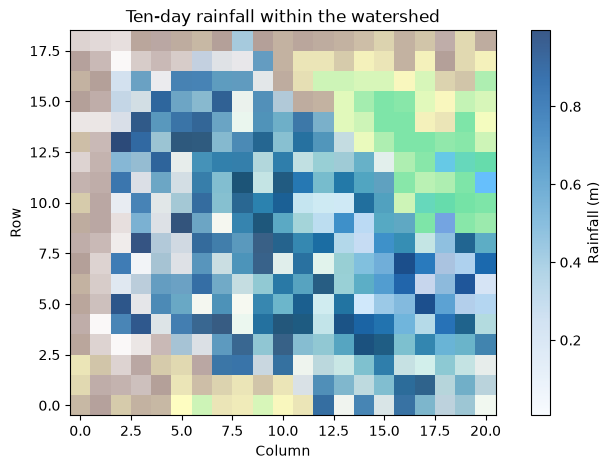

In [12]:
rng = np.random.default_rng(0)  # Reproducible example storm.
monsoon = rng.uniform(0, 1, size=topo3.shape)  # Meters over ten days.
totalrain = shed * monsoon  # MATLAB shed .* monsoon, before infiltration.
runoff_depth = 0.9 * totalrain
runoff_volume_m3 = runoff_depth.sum() * cell_area_m2
seconds_in_ten_days = 10 * 24 * 60 * 60
discharge_m3_s = runoff_volume_m3 / seconds_in_ten_days
print(f"Rain on watershed: {totalrain.sum() * cell_area_m2:,.0f} m³")
print(f"Runoff volume: {runoff_volume_m3:,.0f} m³")
print(f"Average discharge over ten days: {discharge_m3_s:,.2f} m³/s")
print("A 1 km channel width alone does not determine water depth or velocity.")
fig, ax = plt.subplots(figsize=(9, 5))
ax.imshow(topo3, origin="lower", cmap="terrain", alpha=0.6, interpolation="nearest")
image = ax.imshow(np.ma.masked_where(shed == 0, totalrain), origin="lower",
                  cmap="Blues", alpha=0.8, interpolation="nearest")
ax.set(title="Ten-day rainfall within the watershed", xlabel="Column", ylabel="Row")
plt.colorbar(image, ax=ax, label="Rainfall (m)")
plt.show()


### Results: ten-day monsoon

> Figure out how much of that rainfall has landed in our watershed.

**Response:**

> Find what the average flow rate (over the ten days) of water through our 1 km wide channel at the floodpoint must have been, assuming a steady state is reached.

**Response:**